# Data preprocessing
Dataset: Kaggle *Personal Key Indicators of Heart Disease* (2022, with NaNs), a subset of the CDC BRFSS phone survey.

In [11]:
! pip install matplotlib numpy pandas scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [3]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
df = pd.read_csv("data/raw/heart_2022_with_nans.csv.zip")

## 0. Apply EDA data-quality rules

The exploration phase during the EDA found valid ranges for numeric survey answers. Values outside those ranges are treated as missing rather than removing the respondent, because the rest of the survey may still be useful. The imputer handles these new missing values.

BMI can be calculated if it is missing but both height and weight are valid by simply using weight divided by height squared. 

The mixed-response columns are converted into modeling-friendly forms: diabetes becomes an ordered severity/history score, while tetanus and COVID responses are reduced to whether the respondent reports any qualifying Yes response.

In [4]:
plausible_ranges = {
    "PhysicalHealthDays": (0, 30),
    "MentalHealthDays": (0, 30),
    "SleepHours": (3, 16),
    "HeightInMeters": (1.2, 2.2),
    "WeightInKilograms": (30, 250),
    "BMI": (13, 70),
}

invalid_counts = {}
for column, (lower, upper) in plausible_ranges.items():
    invalid = ~df[column].between(lower, upper) & df[column].notna()
    invalid_counts[column] = int(invalid.sum())
    df.loc[invalid, column] = np.nan

valid_height = df["HeightInMeters"].notna()
valid_weight = df["WeightInKilograms"].notna()
reconstruct_bmi = df["BMI"].isna() & valid_height & valid_weight
df.loc[reconstruct_bmi, "BMI"] = (
    df.loc[reconstruct_bmi, "WeightInKilograms"]
    / df.loc[reconstruct_bmi, "HeightInMeters"] ** 2
)
invalid_reconstructed_bmi = ~df["BMI"].between(13, 70) & df["BMI"].notna()
df.loc[invalid_reconstructed_bmi, "BMI"] = np.nan

# Preserve the meaningful order: no diabetes, prediabetes/gestational history, diabetes.
df["HadDiabetes"] = df["HadDiabetes"].map({
    "No": 0,
    "No, pre-diabetes or borderline diabetes": 1,
    "Yes, but only during pregnancy (female)": 1,
    "Yes": 2,
}).astype("Float64")

# Collapse multiple Yes responses into one binary response while retaining missingness.
df["TetanusLast10Tdap"] = df["TetanusLast10Tdap"].map(
    lambda value: "Yes" if isinstance(value, str) and value.startswith("Yes")
    else "No" if isinstance(value, str) else value
)
df["CovidPos"] = df["CovidPos"].replace({
    "Tested positive using home test without a health professional": "Yes",
})

print("Invalid numeric values converted to missing:", invalid_counts)
print(f"BMI values reconstructed from valid height and weight: {int(reconstruct_bmi.sum()):,}")
print("HadDiabetes levels:", sorted(df["HadDiabetes"].dropna().unique().tolist()))
print("TetanusLast10Tdap levels:", df["TetanusLast10Tdap"].value_counts(dropna=False).to_dict())
print("CovidPos levels:", df["CovidPos"].value_counts(dropna=False).to_dict())

Invalid numeric values converted to missing: {'PhysicalHealthDays': 0, 'MentalHealthDays': 0, 'SleepHours': 3150, 'HeightInMeters': 170, 'WeightInKilograms': 106, 'BMI': 298}
BMI values reconstructed from valid height and weight: 2,409
HadDiabetes levels: [0.0, 1.0, 2.0]
TetanusLast10Tdap levels: {'Yes': 241123, 'No': 121493, nan: 82516}
CovidPos levels: {'No': 270055, 'Yes': 124313, nan: 50764}


## 1. Create the HeartDisease target

The EDA combines two survey questions into one clinically broader target. `HeartDisease` is **Yes** if either `HadHeartAttack` or `HadAngina` is Yes, and **No** only when both are No. If one answer is No and the other is missing, or if both answers are missing, the true label cannot be determined; those rows are assigned `Unknown` rather than being forced into a class.

The two source predictors are removed from the dataset because they define the target. The `Unknown` class is retained as unlabeled data. This notebook produces the complete processed dataset; a later modeling file can handle evaluation partitioning.

In [5]:
TARGET = "HeartDisease"
TARGET_SOURCES = ["HadHeartAttack", "HadAngina"]

either_yes = df[TARGET_SOURCES].eq("Yes").any(axis=1)
both_no = df[TARGET_SOURCES].eq("No").all(axis=1)
df[TARGET] = pd.Series(pd.NA, index=df.index, dtype="object")
df.loc[either_yes, TARGET] = "Yes"
df.loc[both_no, TARGET] = "No"
df[TARGET] = df[TARGET].fillna("Unknown").astype("category")

# Remove both source questions to prevent target leakage.
features = df.drop(columns=[TARGET, *TARGET_SOURCES])
labelled_mask = df[TARGET].isin(["Yes", "No"])
unlabelled_mask = df[TARGET].eq("Unknown")
X_all = features
X_labelled = features.loc[labelled_mask]
y_labelled = df.loc[labelled_mask, TARGET].map({"Yes": 1, "No": 0}).astype("int8")
X_unlabelled = features.loc[unlabelled_mask]

print(f"Rows retained: {len(X_all):,}")
print(f"Labelled rows: {len(X_labelled):,}")
print(f"Unlabelled rows retained: {len(X_unlabelled):,}")
print(df[TARGET].value_counts(dropna=False))
print(y_labelled.value_counts(normalize=True).rename("proportion"))

Rows retained: 445,132
Labelled rows: 440,111
Unlabelled rows retained: 5,021
HeartDisease
No         400360
Yes         39751
Unknown      5021
Name: count, dtype: int64
HeartDisease
0    0.90968
1    0.09032
Name: proportion, dtype: float64


## 2. Impute, handle outliers, scale, and encode

The EDA shows that dropping every incomplete row would discard about 45% of respondents. Missingness is also informative: later survey questions have the highest missing rates, and respondents missing some medical-history answers can have different heart-disease rates. Therefore, rows are retained and missing predictor values are imputed inside the preprocessing pipeline.

- Numeric columns use the median, which is less affected by skew and extreme values than the mean.
- Numeric values are clipped to the 1st and 99th percentiles. This limits the influence of implausible extremes without deleting respondents.
- Categorical columns use the mode and are one-hot encoded.
- Numeric features are standardized because later feature selection and PCA are scale-sensitive.

The later modeling workflow can use this consistently transformed dataset for model development and evaluation.

In [6]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    """Clip numeric columns using learned quantile bounds."""

    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        values = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.quantile(values, self.lower, axis=0)
        self.upper_bounds_ = np.quantile(values, self.upper, axis=0)
        return self

    def transform(self, X):
        values = np.asarray(X, dtype=float)
        return np.clip(values, self.lower_bounds_, self.upper_bounds_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


numeric_features = X_all.select_dtypes(include="number").columns.tolist()
categorical_features = X_all.select_dtypes(exclude="number").columns.tolist()
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("outlier_clipper", QuantileClipper()),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot_encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
], remainder="drop")

X_all_encoded = preprocessor.fit_transform(X_all)
X_labelled_encoded = X_all_encoded[labelled_mask.to_numpy()]
X_unlabelled_encoded = X_all_encoded[unlabelled_mask.to_numpy()]
print(f"Encoded dataset shape: {X_all_encoded.shape}")
print(f"Encoded labelled shape: {X_labelled_encoded.shape}")
print(f"Encoded unlabelled shape: {X_unlabelled_encoded.shape}")

Encoded dataset shape: (445132, 146)
Encoded labelled shape: (440111, 146)
Encoded unlabelled shape: (5021, 146)


## 3. Independent feature selection

One-hot encoding expands the original survey variables into 146 numeric columns. To reduce noise and keep the later PCA step manageable, mutual information is used as an independent filter method. It measures how much knowing a feature reduces uncertainty about the binary target and can capture nonlinear relationships, unlike a simple Pearson correlation.

The 50 highest-scoring encoded features are retained. The selector is fit on all labelled rows, while the unlabeled rows are transformed using the resulting feature mask.

In [7]:
n_selected = min(50, X_all_encoded.shape[1])
feature_selector = SelectKBest(mutual_info_classif, k=n_selected)
X_labelled_selected = feature_selector.fit_transform(X_labelled_encoded, y_labelled)
X_all_selected = feature_selector.transform(X_all_encoded)
X_unlabelled_selected = feature_selector.transform(X_unlabelled_encoded)
print(f"Selected {X_all_selected.shape[1]} of {X_all_encoded.shape[1]} encoded features")

Selected 50 of 146 encoded features


### Selected feature table

The table below lists every encoded feature retained by mutual-information selection. The score is calculated from all labelled rows; larger values indicate a stronger estimated dependence on `HeartDisease`.

In [8]:
encoded_feature_names = preprocessor.get_feature_names_out()
selected_feature_table = (
    pd.DataFrame({
        "feature": encoded_feature_names[feature_selector.get_support()],
        "mutual_information": feature_selector.scores_[feature_selector.get_support()],
    })
    .sort_values("mutual_information", ascending=False)
    .reset_index(drop=True)
)
selected_feature_table["mutual_information"] = selected_feature_table["mutual_information"].round(4)
print(selected_feature_table.to_string(index=False))

                                                                        feature  mutual_information
                                                      categorical__HadStroke_No              0.1095
                                        categorical__BlindOrVisionDifficulty_No              0.1075
                                               categorical__HadKidneyDisease_No              0.1073
                                                      categorical__ChestScan_No              0.1003
                                              categorical__DifficultyWalking_No              0.0961
                                                   categorical__HadArthritis_No              0.0950
                                      categorical__DifficultyDressingBathing_No              0.0948
                                                  categorical__PneumoVaxEver_No              0.0924
                                               categorical__HighRiskLastYear_No              0.0910


### Interpretation of feature selection

The selected features are dominated by indicators of physical functioning and chronic conditions. The highest mutual-information features include `HadStroke_No`, `HadKidneyDisease_No`, `BlindOrVisionDifficulty_No`, `ChestScan_No`, `HadArthritis_No`, `DifficultyWalking_No`, `PneumoVaxEver_No`, `DifficultyDressingBathing_No`, and `HadDiabetes_No`. This is consistent with the EDA: heart disease is associated with broader health status, mobility limitations, chronic disease history, and healthcare utilization.

Mutual information measures dependence, not direction. A high score for a `_No` indicator does not mean that answering No causes heart disease; it means that this response helps distinguish the target classes. One-hot encoding also creates complementary levels, such as `DifficultyWalking_No` and `DifficultyWalking_Yes`, so individual category scores should be interpreted as parts of one survey variable rather than independent medical risk factors.

The presence of `ChestScan` among the strongest selected variables deserves caution. It may be predictive because people with suspected heart problems are more likely to receive a scan, which is useful for prediction but can represent diagnosis-related leakage in a real deployment. Feature selection identifies predictive association; it does not establish clinical causality.

## 4. Dimensionality reduction with PCA

PCA replaces the 50 selected features with orthogonal principal components. This can reduce redundancy among correlated survey variables and produce a compact representation for downstream models. The number of components is chosen to retain at least 95% of the variance.

The resulting processed dataset has the same columns for labelled and unlabeled rows and is ready for a later modeling workflow.

In [23]:
pca = PCA(n_components=0.95, svd_solver="full", random_state=42)
X_all_processed = pca.fit_transform(X_all_selected)
selected_feature_names = preprocessor.get_feature_names_out()[feature_selector.get_support()]
loadings = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=selected_feature_names,
    columns=[f"PC{i}" for i in range(1, pca.n_components_ + 1)],
)
pca_loading_table = loadings.rename_axis("feature").reset_index()
print(f"Processed dataset shape: {X_all_processed.shape}")
print(f"Explained variance retained: {pca.explained_variance_ratio_.sum():.3f}")
component_table = (
    pca_loading_table[["feature", "PC1", "PC2"]]
    .assign(_absolute_loading=lambda table: table[["PC1", "PC2"]].abs().max(axis=1))
    .sort_values("_absolute_loading", ascending=False)
    .drop(columns="_absolute_loading")
)
print("PC1 and PC2 loading table (ordered by absolute loading):")
print(component_table.round(4).to_string(index=False))

Processed dataset shape: (445132, 26)
Explained variance retained: 0.954
PC1 and PC2 loading table (ordered by absolute loading):
                                                                        feature     PC1     PC2
                                                    numeric__PhysicalHealthDays  0.7767 -0.0350
                                                      numeric__MentalHealthDays  0.6000 -0.5184
                                                            numeric__SleepHours -0.2253  0.5775
                                                           numeric__HadDiabetes  0.4705  0.5712
                                             categorical__DifficultyWalking_Yes  0.1961  0.0616
                                              categorical__DifficultyWalking_No -0.1961 -0.0616
                                                   categorical__HadArthritis_No -0.1953 -0.1220
                                                  categorical__HadArthritis_Yes  0.1953  0.1220
      

### Biplot for PCA

PC1 and PC2 loading table (ordered by absolute loading):
                                                                        feature     PC1     PC2
                                                    numeric__PhysicalHealthDays  0.7767 -0.0350
                                                      numeric__MentalHealthDays  0.6000 -0.5184
                                                            numeric__SleepHours -0.2253  0.5775
                                                           numeric__HadDiabetes  0.4705  0.5712
                                             categorical__DifficultyWalking_Yes  0.1961  0.0616
                                              categorical__DifficultyWalking_No -0.1961 -0.0616
                                                   categorical__HadArthritis_No -0.1953 -0.1220
                                                  categorical__HadArthritis_Yes  0.1953  0.1220
                                                 categorical__PneumoVaxEver_Yes

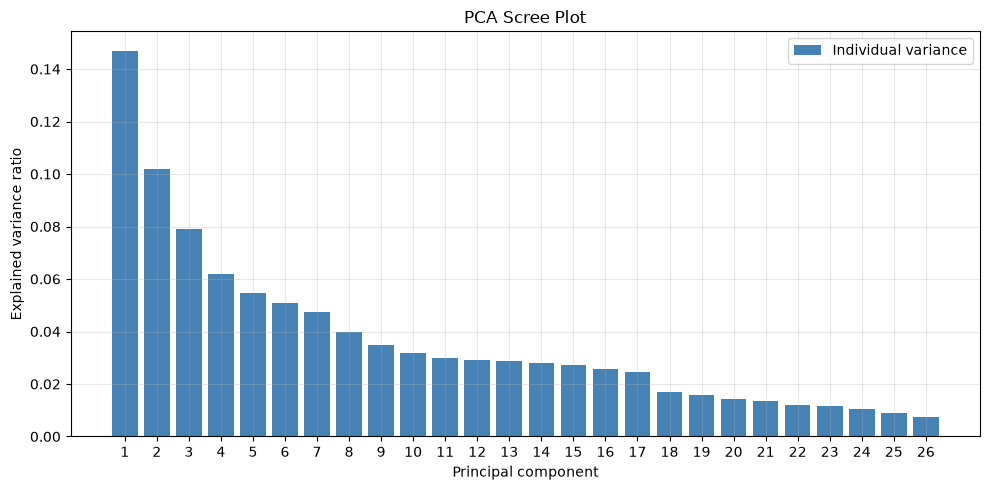

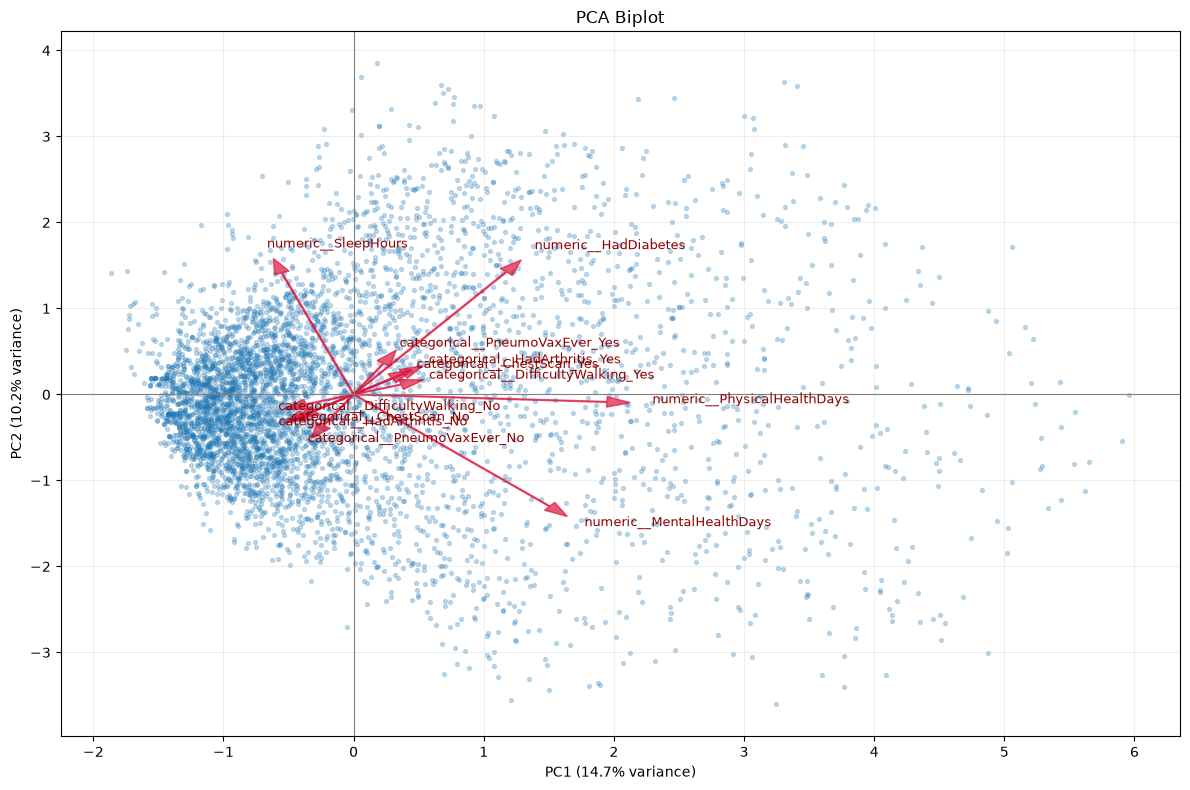

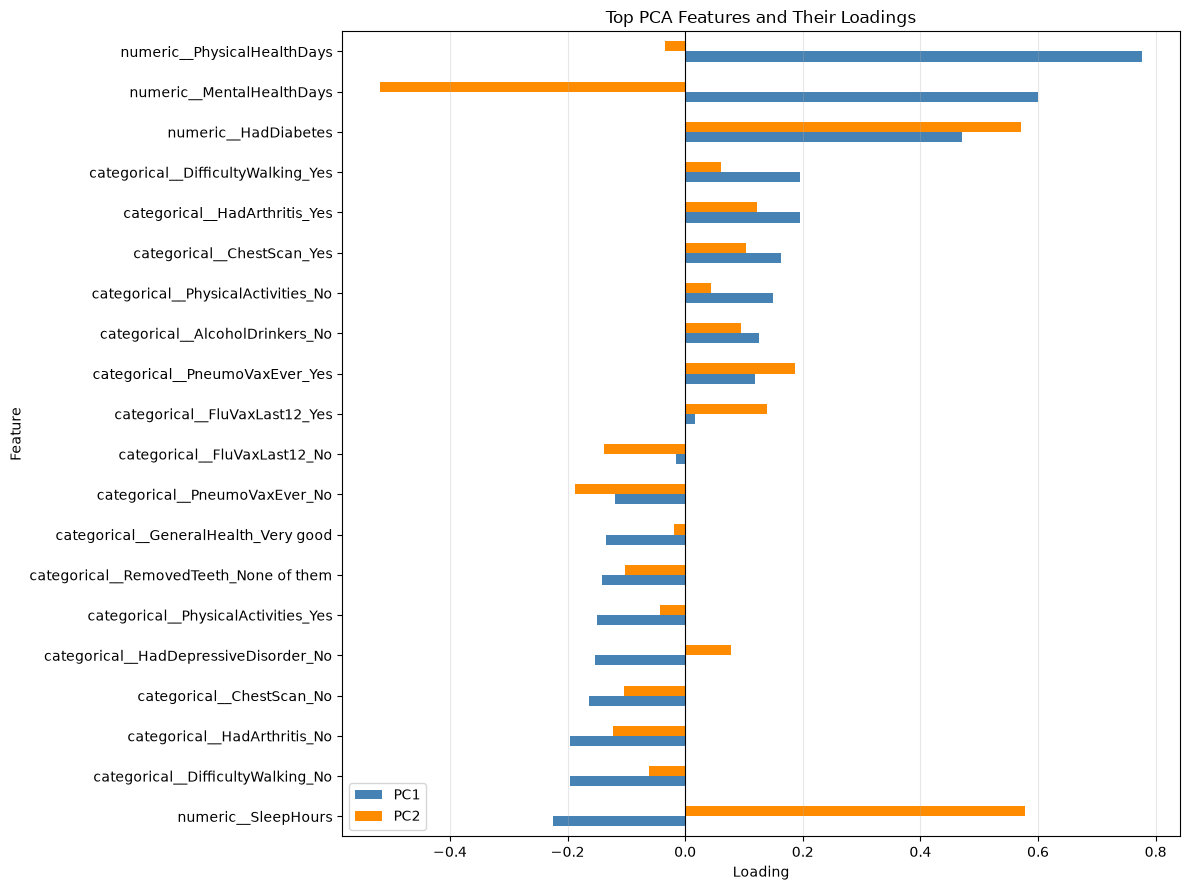

In [24]:
import matplotlib.pyplot as plt

# Recover names of the selected encoded features
encoded_feature_names = preprocessor.get_feature_names_out()
selected_feature_names = encoded_feature_names[feature_selector.get_support()]

# PCA loadings: rows = features, columns = principal components
loadings = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=selected_feature_names,
    columns=[f"PC{i}" for i in range(1, pca.n_components_ + 1)],
)

# PC1 and PC2 loading tables, ordered by absolute loading while retaining signed values.
pca_loading_table = loadings.rename_axis("feature").reset_index()
component_table = (
    pca_loading_table[["feature", "PC1", "PC2"]]
    .assign(_absolute_loading=lambda table: table[["PC1", "PC2"]].abs().max(axis=1))
    .sort_values("_absolute_loading", ascending=False)
    .drop(columns="_absolute_loading")
)
print("PC1 and PC2 loading table (ordered by absolute loading):")
print(component_table.round(4).to_string(index=False))

# 1. Scree plot
explained_variance = pca.explained_variance_ratio_

plt.figure(figsize=(10, 5))
plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    color="steelblue",
    label="Individual variance",
)
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA Scree Plot")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("figures/preprocessing/pca_scree_plot.png", dpi=200)
plt.show()

# 2. PCA biplot using a sample of observations
rng = np.random.default_rng(42)
sample_size = min(5000, len(X_all_processed))
sample_idx = rng.choice(len(X_all_processed), sample_size, replace=False)

scores = X_all_processed[sample_idx, :2]

fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(scores[:, 0], scores[:, 1], s=8, alpha=0.25)

# Label the strongest features for PC1 and PC2
top_features = (
    loadings[["PC1", "PC2"]]
    .abs()
    .max(axis=1)
    .nlargest(12)
    .index
)

arrow_scale = max(np.ptp(scores[:, 0]), np.ptp(scores[:, 1])) * 0.35

for feature in top_features:
    x = loadings.loc[feature, "PC1"] * arrow_scale
    y_value = loadings.loc[feature, "PC2"] * arrow_scale
    ax.arrow(
        0, 0, x, y_value,
        color="crimson",
        alpha=0.7,
        width=0.01,
        head_width=0.12,
        length_includes_head=True,
    )
    ax.text(x * 1.08, y_value * 1.08, feature, color="darkred", fontsize=9)

ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel(f"PC1 ({explained_variance[0] * 100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({explained_variance[1] * 100:.1f}% variance)")
ax.set_title("PCA Biplot")
plt.grid(alpha=0.2)
fig.tight_layout()
fig.savefig("figures/preprocessing/pca_biplot.png", dpi=200)
plt.show()

# 3. Features versus loadings for PC1 and PC2
loading_features = (
    loadings[["PC1", "PC2"]]
    .abs()
    .max(axis=1)
    .nlargest(20)
    .index
)

loading_plot = loadings.loc[loading_features, ["PC1", "PC2"]].sort_values("PC1")

ax = loading_plot.plot.barh(figsize=(12, 9), color=["steelblue", "darkorange"])
ax.set_xlabel("Loading")
ax.set_ylabel("Feature")
ax.set_title("Top PCA Features and Their Loadings")
ax.axvline(0, color="black", linewidth=0.8)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("figures/preprocessing/pca_feature_loadings.png", dpi=200)
plt.show()

# To display all PCs
# loadings.loc[
#     loadings.abs().max(axis=1).nlargest(20).index
# ].sort_values("PC1", key=np.abs, ascending=False)

## 5. Export the combined processed dataset

Original row index is retained as `row_id`, and the three-level `HeartDisease` label is retained as `Yes`, `No`, or `Unknown` alongside all retained PCA components.

In [25]:
processed_features = pd.DataFrame(
    X_all_processed,
    index=X_all.index,
    columns=[f"PC{i}" for i in range(1, X_all_processed.shape[1] + 1)],
)

processed_dataset = processed_features.copy()
processed_dataset.insert(0, "row_id", processed_dataset.index)
processed_dataset.insert(1, TARGET, df.loc[processed_dataset.index, TARGET].astype(str).to_numpy())

output_path = "data/processed/heart_disease_preprocessed.csv"
Path(output_path).parent.mkdir(parents=True, exist_ok=True)
processed_dataset.to_csv(output_path, index=False)

print(f"Wrote {len(processed_dataset):,} rows and {processed_dataset.shape[1]:,} columns to {output_path}")
print(processed_dataset[TARGET].value_counts(dropna=False))

Wrote 445,132 rows and 28 columns to data/processed/heart_disease_preprocessed.csv
HeartDisease
No         400360
Yes         39751
Unknown      5021
Name: count, dtype: int64


Save PCA results

In [26]:
pca_with_labels = pd.DataFrame(
    X_all_processed,
    index=X_all.index,
    columns=[f"PC{i}" for i in range(1, X_all_processed.shape[1] + 1)],
)

pca_with_labels.insert(0, "row_id", pca_with_labels.index)
pca_with_labels.insert(
    1,
    TARGET,
    df.loc[pca_with_labels.index, TARGET].astype(str).to_numpy(),
)

pca_output_path = "data/processed/heart_disease_pca_with_labels.csv"
Path(pca_output_path).parent.mkdir(parents=True, exist_ok=True)
pca_with_labels.to_csv(pca_output_path, index=False)

print(f"Saved PCA scores and labels to {pca_output_path}")
print(pca_with_labels.head())

Saved PCA scores and labels to data/processed/heart_disease_pca_with_labels.csv
   row_id HeartDisease       PC1       PC2       PC3       PC4       PC5  \
0       0           No  0.005856  1.879366 -0.631521  1.705126  0.062157   
1       1           No -0.744033 -0.593608 -0.601390 -0.198305  0.962192   
2       2           No -0.569120 -1.363107 -1.078786 -0.174359  0.346907   
3       3           No -0.221506  0.727933 -0.151059 -1.032085 -0.707830   
4       4           No -0.932857  0.905866  1.202015 -0.140822  0.303075   

        PC6       PC7       PC8       PC9      PC10      PC11      PC12  \
0  0.876527  1.115704 -0.136405  0.403109 -0.415500 -0.232906 -0.080694   
1 -0.051836  1.743412  0.649109  0.141558  0.093815 -0.527450 -0.276660   
2  0.078978  1.154746 -0.778770  0.641079  0.812691  0.375613  0.025263   
3 -1.153888  0.740575  0.326022  0.441734  0.557094 -1.086720 -0.101628   
4 -0.513640  0.288974 -0.004725 -0.024393  0.865500 -1.308758 -0.362992   

       PC13 